# Crank-Nicolson

## Problem
Same as notebook 07, $u_t = u_{xx}$ with $u(x,0)=\sin(\pi x)$ and exact solution $e^{-\pi^2 t}\sin(\pi x)$.

## Discretization
Average of the explicit and implicit schemes

$$
\left(1 + r\right) u_i^{n+1} - \frac{r}{2}\left(u_{i-1}^{n+1} + u_{i+1}^{n+1}\right) = \left(1 - r\right) u_i^n + \frac{r}{2}\left(u_{i-1}^n + u_{i+1}^n\right)
$$

The left side is the same tridiagonal matrix at every step, so it is factored once.

## Code

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from heat import crank_nicolson, hat, hat_exact

In [2]:
T_END = 0.5
ex = lambda x, t: np.exp(-np.pi**2*t)*np.sin(np.pi*x)

In [3]:
N = 20
h = 1/N
x = np.linspace(0, 1, N+1)
r = 5
nt = int(round(T_END/(r*h**2)))
u, hist = crank_nicolson(np.sin(np.pi*x), r, nt)
print(f"nt = {nt}, max|u| = {np.max(np.abs(hist)):.3f}, err = {np.max(np.abs(u-ex(x, T_END))):.3e}")

nt = 40, max|u| = 1.000, err = 2.813e-05


### Convergence in time

In [4]:
N = 400
x = np.linspace(0, 1, N+1)
res_t = []
for nt in [4, 8, 16, 32, 64]:
    u, hist = crank_nicolson(np.sin(np.pi*x), T_END/nt*N**2, nt)
    res_t.append({'dt': T_END/nt, 'err': np.max(np.abs(u-ex(x, T_END)))})
dft = pd.DataFrame(res_t)
dft['order'] = np.log2(dft['err'].shift()/dft['err'])
dft

,dt,err,order
0,0.125000,0.004038,NaN
1,0.062500,0.001100,1.875913
2,0.031250,0.000280,1.976098
3,0.015625,0.000070,1.996984
4,0.007812,0.000017,2.009862


### Convergence in space

In [5]:
nt = 4000
res_h = []
for N in [4, 8, 16, 32, 64]:
    x = np.linspace(0, 1, N+1)
    u, hist = crank_nicolson(np.sin(np.pi*x), T_END/nt*N**2, nt)
    res_h.append({'h': 1/N, 'err': np.max(np.abs(u-ex(x, T_END)))})
dfh = pd.DataFrame(res_h)
dfh['order'] = np.log2(dfh['err'].shift()/dfh['err'])
dfh

,h,err,order
0,0.250000,0.002029,NaN
1,0.125000,0.000468,2.115006
2,0.062500,0.000115,2.028796
3,0.031250,0.000029,2.007358
4,0.015625,0.000007,2.002480


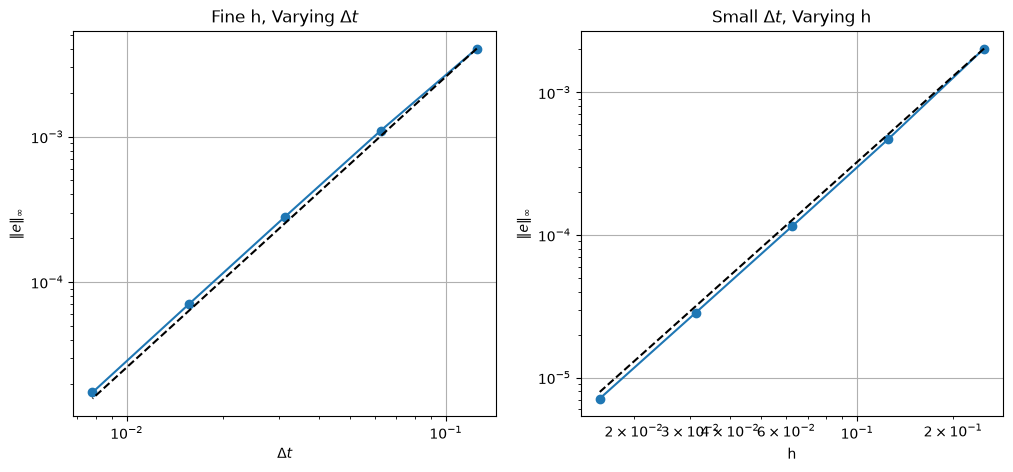

In [6]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.loglog(dft['dt'], dft['err'], 'o-')
plt.loglog(dft['dt'], dft['err'][0]*(dft['dt']/dft['dt'][0])**2, 'k--')
plt.xlabel(r"$\Delta t$")
plt.ylabel(r"$\|e\|_\infty$")
plt.title(r"Fine h, Varying $\Delta t$")
plt.grid(True)
plt.subplot(1, 2, 2)
plt.loglog(dfh['h'], dfh['err'], 'o-')
plt.loglog(dfh['h'], dfh['err'][0]*(dfh['h']/dfh['h'][0])**2, 'k--')
plt.xlabel("h")
plt.ylabel(r"$\|e\|_\infty$")
plt.title(r"Small $\Delta t$, Varying h")
plt.grid(True)
plt.savefig("../figures/08_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

### Hat initial condition

In [7]:
N = 50
x = np.linspace(0, 1, N+1)
r = 5
nt = 5
t = nt*r/N**2
u, hist = crank_nicolson(hat(x), r, nt)
xf = np.linspace(0, 1, 501)

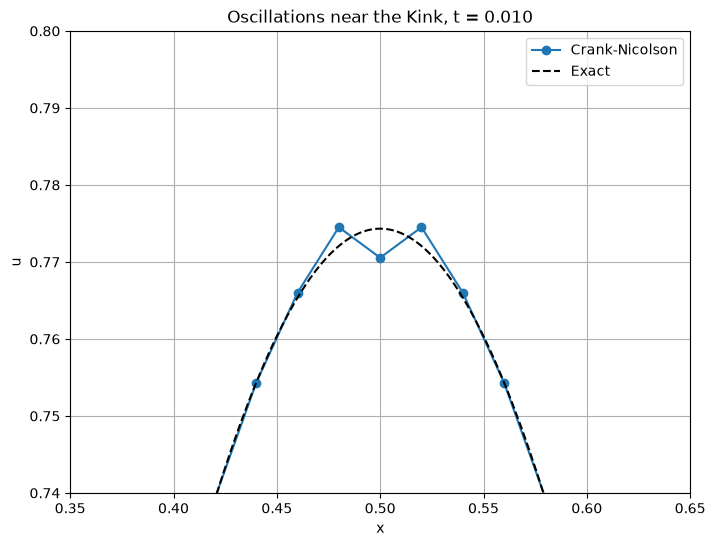

In [8]:
plt.figure(figsize=(8, 6))
plt.plot(x, u, 'o-', label="Crank-Nicolson")
plt.plot(xf, hat_exact(xf, t), 'k--', label="Exact")
plt.xlim(0.35, 0.65)
plt.ylim(0.74, 0.8)
plt.xlabel("x")
plt.ylabel("u")
plt.title(f"Oscillations near the Kink, t = {t:.3f}")
plt.legend()
plt.grid(True)
plt.savefig("../figures/08_kink.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
Crank-Nicolson stays stable at r = 5 and the error is second order in both $\Delta t$ and h. With the hat start a small dip shows up at the kink because the high modes are barely damped at large r.